In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Standardization practice

In [2]:
social_data = pd.read_csv("E:\Data Science\Machine Learning\data\Social_Network_Ads.csv")
social_data = social_data.iloc[:, 2:]

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Anwoy\AppData\Local\Temp\ipykernel_2252\3546203934.py:1: SyntaxWarning: invalid escape sequence '\D'
  social_data = pd.read_csv("E:\Data Science\Machine Learning\data\Social_Network_Ads.csv")


In [3]:
social_data.sample(10)

,Age,EstimatedSalary,Purchased
353,37,57000,0
281,35,61000,0
223,60,102000,1
34,27,90000,0
120,36,75000,0
399,49,36000,1
91,30,116000,0
17,45,26000,1
201,49,74000,0
325,41,60000,0


In [4]:
social_data.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [5]:
X = social_data.drop("Purchased", axis = 1)
y = social_data.iloc[:, -1]

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state = 42)

In [7]:
X_test

,Age,EstimatedSalary
209,46,22000
280,59,88000
33,28,44000
210,48,96000
93,29,28000
...,...,...
60,27,20000
79,26,17000
285,37,93000
305,42,54000


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
from sklearn.svm import SVC

svc_model = SVC()
svc_model.fit(X_train_scaled, y_train)

SVC()

In [10]:
y_pred = svc_model.predict(X_test_scaled)

output = accuracy_score(y_pred, y_test)
print(f"accuracy score for standardized data is: {output}")

accuracy score for standardized data is: 0.9416666666666667


In [11]:
# for without scaled data
svc_model.fit(X_train, y_train)
output2 = accuracy_score(svc_model.predict(X_test), y_test)
print(f"accuracy score for non-standardized data is: {output2}")

accuracy score for non-standardized data is: 0.7416666666666667


### graphical comparison

In [12]:
X_train_scaled_m = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_m = pd.DataFrame(X_test_scaled, columns=X_test.columns)

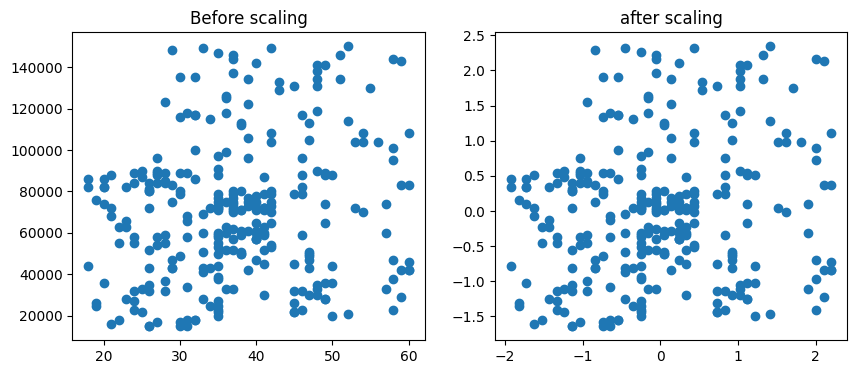

In [13]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (10, 4) )
# plotting before scaled data
ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before scaling")

# after scaling
ax2.scatter(X_train_scaled_m['Age'], X_train_scaled_m['EstimatedSalary'])
ax2.set_title("after scaling")
plt.show()

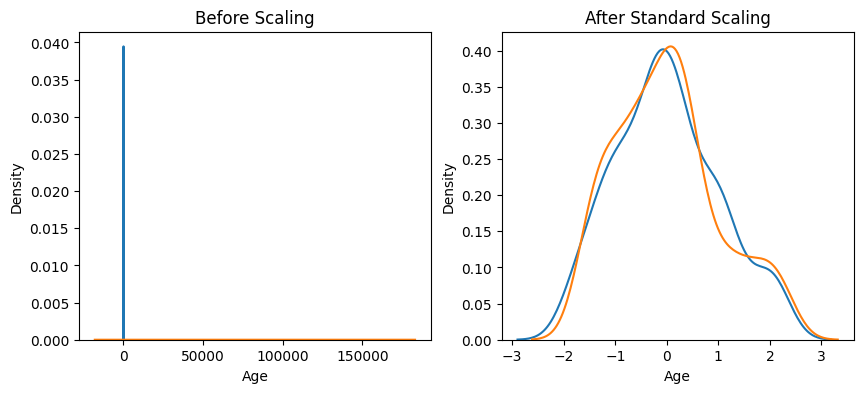

In [14]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10,4))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled_m['Age'], ax=ax2)
sns.kdeplot(X_train_scaled_m['EstimatedSalary'], ax=ax2)
plt.show()

### Normalization

In [69]:
social_data.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [15]:
X, y = social_data.iloc[:, 0:2], social_data.iloc[:,2]

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state = 42)

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
X_train.describe()

,Age,EstimatedSalary
count,280.000000,280.000000
mean,37.575000,70589.285714
std,10.196005,33948.504534
min,18.000000,15000.000000
25%,30.000000,44000.000000
50%,37.000000,71000.000000
75%,45.000000,88000.000000
max,60.000000,150000.000000


In [18]:
pd.DataFrame(X_train_scaled).describe()

,0,1
count,280.000000,280.000000
mean,0.466071,0.411772
std,0.242762,0.251470
min,0.000000,0.000000
25%,0.285714,0.214815
50%,0.452381,0.414815
75%,0.642857,0.540741
max,1.000000,1.000000


In [19]:
from sklearn.svm import SVC

svc_model = SVC()
svc_model.fit(X_train_scaled, y_train)

y_pred = svc_model.predict(X_test_scaled)
accuracy = accuracy_score(y_pred, y_test)
print(f"accuracy score for MinMax scaler is: {accuracy}")
print(f"accuracy score for standardized data is: {output}")

accuracy score for MinMax scaler is: 0.9333333333333333
accuracy score for standardized data is: 0.9416666666666667


Standardized data is performing better minmax scaled data.